# Decision Tree and Random Forest

### Author
   * Jonathan Sancho Loaiza

## Problem Analysis (CRISP-DM 1: Business Understanding)

One of the main challenges people face today is getting access to goods and
services they cannot pay for in a single step, so many of them ask a bank for a
loan. Not every applicant is able to pay that loan back, and the bank has to
decide, before handing out the money, which applicants are safe and which ones
are likely to stop paying.

The goal of this notebook is to build a model that classifies a credit
applicant into one of two groups: an applicant who paid the loan back, and an
applicant who defaulted on it. The response variable is `default`, which the
dataset codes as 1 when the client paid and 2 when the client did not. Every
other column is a candidate predictor: the balance of the checking account, the
duration and the amount of the loan, the credit history, the age of the
applicant, the job and so on.

The two possible mistakes do not cost the bank the same. Rejecting a client who
would have paid costs the interest of one loan, while approving a client who
defaults costs the loan itself. The German credit dataset is normally used with
a cost of five to one between the two errors, so throughout the notebook the
class of interest is the defaulter and the metric that matters most is how many
of the real defaulters the model manages to catch.

Two models are trained on the same data and compared on the same split: a single
decision tree, which is easy to read and explain to a credit officer, and a
random forest, which averages many trees and usually predicts better at the cost
of that readability.

### Libraries

In [1]:
# Dataset handling
import os
import pandas as pd
import numpy as np

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Models
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Split and validation
from sklearn.model_selection import train_test_split, cross_val_score

# Evaluation
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_curve, roc_auc_score)

# Same seed everywhere, so the notebook gives the same numbers on every run
SEED = 4161
np.random.seed(SEED)

## Data Understanding (CRISP-DM 2)

The file `credit.csv` is the German credit dataset. Each row is one credit
applicant of a German bank and each column one attribute recorded about that
applicant or about the loan being requested.

In [2]:
# Load the data. The file is read from the notebook's own folder, and if it is
# not there the Colab sample_data folder is tried, so the notebook runs in both
FILE = 'credit.csv'
path = FILE if os.path.exists(FILE) else '/content/sample_data/' + FILE
credit = pd.read_csv(path)

# First records
credit.head()

,checking_balance,months_loan_duration,credit_history,purpose,amount,savings_balance,employment_length,installment_rate,personal_status,other_debtors,...,property,age,installment_plan,housing,existing_credits,default,dependents,telephone,foreign_worker,job
0,< 0 DM,6,critical,radio/tv,1169,unknown,> 7 yrs,4,single male,none,...,real estate,67,none,own,2,1,1,yes,yes,skilled employee
1,1 - 200 DM,48,repaid,radio/tv,5951,< 100 DM,1 - 4 yrs,2,female,none,...,real estate,22,none,own,1,2,1,none,yes,skilled employee
2,unknown,12,critical,education,2096,< 100 DM,4 - 7 yrs,2,single male,none,...,real estate,49,none,own,1,1,2,none,yes,unskilled resident
3,< 0 DM,42,repaid,furniture,7882,< 100 DM,4 - 7 yrs,2,single male,guarantor,...,building society savings,45,none,for free,1,1,2,none,yes,skilled employee
4,< 0 DM,24,delayed,car (new),4870,< 100 DM,1 - 4 yrs,3,single male,none,...,unknown/none,53,none,for free,2,2,2,none,yes,skilled employee


The first rows already show the two kinds of column the dataset mixes. Some are
text that names a category, such as `checking_balance` with values like
`< 0 DM` or `unknown`, and some are plain numbers, such as `amount`, `age` or
`months_loan_duration`. DM stands for Deutsche Mark, the German currency at the
time the data was collected.

The column `default` is the one to predict. It holds 1 for a client who repaid
the loan and 2 for a client who did not.

In [3]:
# Number of records
print("Record count:", len(credit))
# Number of columns
print("Column count:", len(credit.columns))
# Rows and columns
print("Rows and columns:", credit.shape)
# Dataset information
credit.info()

Record count: 1000
Column count: 21
Rows and columns: (1000, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   checking_balance      1000 non-null   object
 1   months_loan_duration  1000 non-null   int64 
 2   credit_history        1000 non-null   object
 3   purpose               1000 non-null   object
 4   amount                1000 non-null   int64 
 5   savings_balance       1000 non-null   object
 6   employment_length     1000 non-null   object
 7   installment_rate      1000 non-null   int64 
 8   personal_status       1000 non-null   object
 9   other_debtors         1000 non-null   object
 10  residence_history     1000 non-null   int64 
 11  property              1000 non-null   object
 12  age                   1000 non-null   int64 
 13  installment_plan      1000 non-null   object
 14  housing               10

The dataset has 1000 records and 21 columns, so 20 possible predictors plus the
response. The `info()` output lists, for every column, how many values are not
empty and which type pandas assigned to it. Thirteen columns are text and seven
are whole numbers, and all of them report 1000 non null values, which is the
first sign that nothing is missing.

The seven numeric columns are the duration of the loan in months, the amount
requested, the installment rate as a percentage of the income, how many years
the client has lived at the current address, the age, how many credits the
client already has at the bank, and how many people depend on the client.

In [4]:
# Check for empty values
print(credit.isnull().any().sum(), ' / ', len(credit.columns))

0  /  21


The left number counts columns with at least one empty value and the right one
counts all the columns. Zero out of 21 means no column has an empty cell, so no
record has to be dropped and no value has to be filled in.

In [5]:
# Check for duplicated records
print("Duplicated rows:", credit.duplicated().sum())

# The records involved
credit[credit.duplicated(keep=False)]

Duplicated rows: 0


,checking_balance,months_loan_duration,credit_history,purpose,amount,savings_balance,employment_length,installment_rate,personal_status,other_debtors,...,property,age,installment_plan,housing,existing_credits,default,dependents,telephone,foreign_worker,job


There are no repeated rows, so the table below the count comes out empty. Every
one of the 1000 records is a different applicant, and no client is counted twice
when the data is split into training and test.

Class counts:
default
1    700
2    300
Name: count, dtype: int64

Class share:
default
1    0.7
2    0.3
Name: proportion, dtype: float64


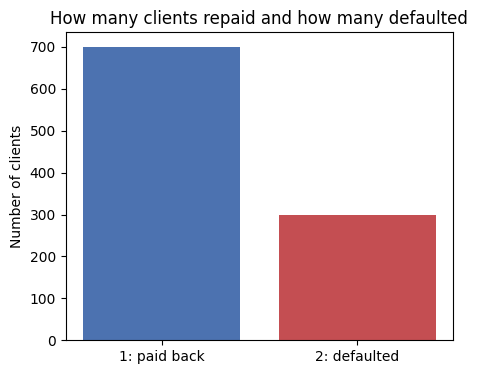

In [6]:
# How the response variable is distributed
counts = credit['default'].value_counts().sort_index()
print("Class counts:")
print(counts)
print("\nClass share:")
print(credit['default'].value_counts(normalize=True).sort_index().round(3))

plt.figure(figsize=(5, 4))
plt.bar(['1: paid back', '2: defaulted'], counts.values, color=['#4c72b0', '#c44e52'])
plt.title('How many clients repaid and how many defaulted')
plt.ylabel('Number of clients')
plt.show()

The bar chart counts clients in each class, with the height of the bar being the
number of records. There are 700 clients who repaid and 300 who defaulted, that
is 70 percent against 30 percent.

That imbalance is worth keeping in mind for the rest of the notebook. A model
that always answered that the client repays, without looking at a single
variable, would already be right 70 percent of the time, so an accuracy of 70
percent is the floor and not a good result. Any model built here has to beat
that number to be worth anything, and the interesting question is how many of
the 300 defaulters it can find.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

The first thing to look at is how the numeric variables behave inside each of
the two classes. If the distribution of a variable is the same for clients who
repaid and clients who defaulted, that variable carries no information about the
response.

In [7]:
# Summary of the numeric columns
credit.describe().T

,count,mean,std,min,25%,50%,75%,max
months_loan_duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_history,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
default,1000.0,1.300,0.458487,1.0,1.0,1.0,2.00,2.0
dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0


Each row of this table is a numeric column and each column a statistic: the
count of values, the mean, the standard deviation, the smallest value, the three
quartiles and the largest value.

The loans last 20.9 months on average. The amount requested averages 3271 DM
with a standard deviation of 2823, and its maximum sits far above the third
quartile, so the variable has a long tail to the right. The clients are 35.5
years old on average. The remaining four columns are small counts rather than
measurements: `installment_rate`, `residence_history` and `existing_credits`
move between 1 and 4, and `dependents` only takes the values 1 and 2.

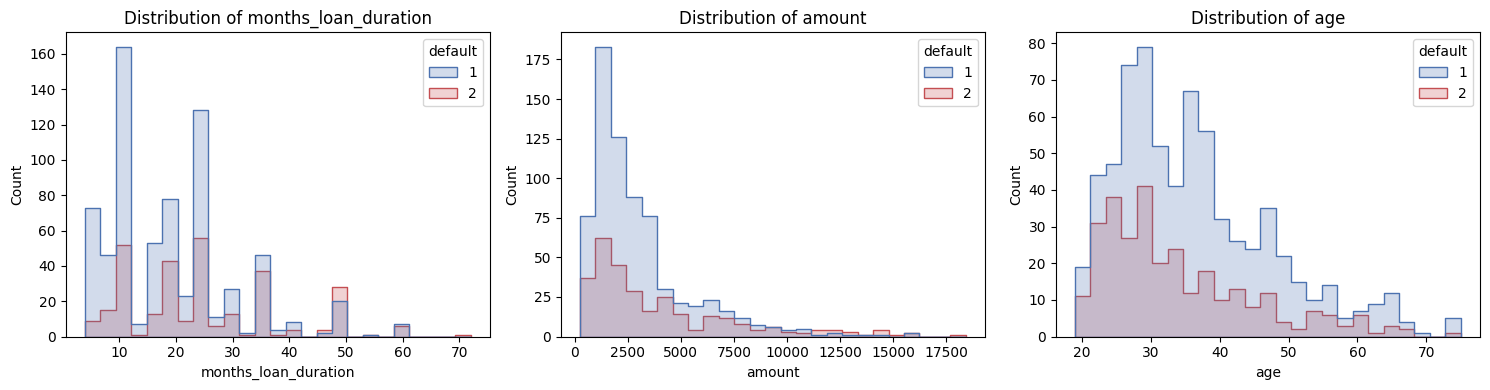

In [8]:
# Distribution of the three main numeric variables, split by class
numeric_main = ['months_loan_duration', 'amount', 'age']

plt.figure(figsize=(15, 4))
for i, column in enumerate(numeric_main, start=1):
    plt.subplot(1, 3, i)
    sns.histplot(data=credit, x=column, hue='default', bins=25,
                 palette=['#4c72b0', '#c44e52'], element='step')
    plt.title('Distribution of ' + column)
plt.tight_layout()
plt.show()

Each panel is a histogram: the horizontal axis is the value of the variable, the
height of a bar is how many clients fall in that range, and the two colors are
the two classes, blue for the clients who repaid and red for the ones who
defaulted. Because there are more than twice as many clients in the first class,
the blue curve is taller almost everywhere and what matters is the shape, not
the height.

The duration of the loan and the amount both pile up on the left and stretch out
to the right, which is the long tail already visible in the summary table. In
both of them the red curve is shifted slightly to the right of the blue one, so
longer and larger loans default more often. Age behaves the other way around,
with the red curve leaning towards the younger clients.

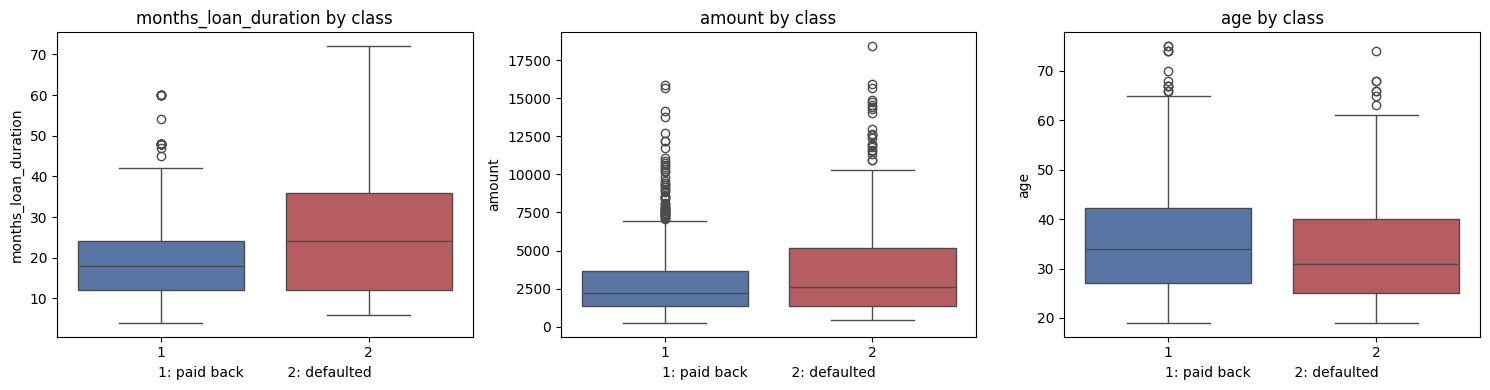

         months_loan_duration  amount   age
default                                    
1                        18.0  2244.0  34.0
2                        24.0  2574.5  31.0


In [9]:
# The same three variables as box plots, one box per class
plt.figure(figsize=(15, 4))
for i, column in enumerate(numeric_main, start=1):
    plt.subplot(1, 3, i)
    sns.boxplot(data=credit, x='default', y=column,
                hue='default', palette=['#4c72b0', '#c44e52'], legend=False)
    plt.title(column + ' by class')
    plt.xlabel('1: paid back          2: defaulted')
plt.tight_layout()
plt.show()

# The numbers behind the boxes
print(credit.groupby('default')[numeric_main].median())

A box plot summarises a variable with five numbers. The box goes from the first
quartile to the third quartile, so it holds the middle half of the clients, the
line inside the box is the median, the whiskers reach out to the most extreme
values that are still close to the box, and the dots beyond them are the
observations that sit far from the rest.

The medians printed under the plots say the same thing in numbers: the clients
who defaulted asked for longer and larger loans and are younger than the ones
who repaid. The boxes overlap a lot, so none of these three variables separates
the classes on its own, but all three push in a consistent direction.

In [10]:
# Default rate inside each level of the most promising text variables
for column in ['checking_balance', 'credit_history', 'savings_balance']:
    share = pd.crosstab(credit[column], credit['default'], normalize='index')
    share.columns = ['paid back', 'defaulted']
    print('Default rate by ' + column)
    print(share.round(3))
    print()

Default rate by checking_balance
                  paid back  defaulted
checking_balance                      
1 - 200 DM            0.610      0.390
< 0 DM                0.507      0.493
> 200 DM              0.778      0.222
unknown               0.883      0.117

Default rate by credit_history
                        paid back  defaulted
credit_history                              
critical                    0.829      0.171
delayed                     0.682      0.318
fully repaid                0.375      0.625
fully repaid this bank      0.429      0.571
repaid                      0.681      0.319

Default rate by savings_balance
                 paid back  defaulted
savings_balance                      
101 - 500 DM         0.670      0.330
501 - 1000 DM        0.825      0.175
< 100 DM             0.640      0.360
> 1000 DM            0.875      0.125
unknown              0.825      0.175



Each table takes one text variable, puts one of its levels on every row, and
reports which share of the clients in that row repaid and which share defaulted.
The two numbers of a row add up to 1, so a row with 0.49 in the second column
means that almost half of those clients defaulted.

The balance of the checking account is the strongest signal in the whole
dataset. Clients whose account was overdrawn defaulted 49 percent of the time,
those between 1 and 200 DM 39 percent, those above 200 DM 22 percent, and the
group recorded as unknown only 12 percent. That last group is not a missing
value to be filled in, it means the client has no checking account at this bank,
and it turns out to be the safest group of all.

The credit history table looks backwards at first, because the level named
critical defaults less often than the levels that say the client fully repaid a
previous loan. That is a known trait of this dataset: a client labelled critical
already has a long record at this bank, while a client whose previous loans are
closed is one the bank currently knows nothing about. The savings balance
repeats the pattern of the checking account, with the lowest savings defaulting
the most.

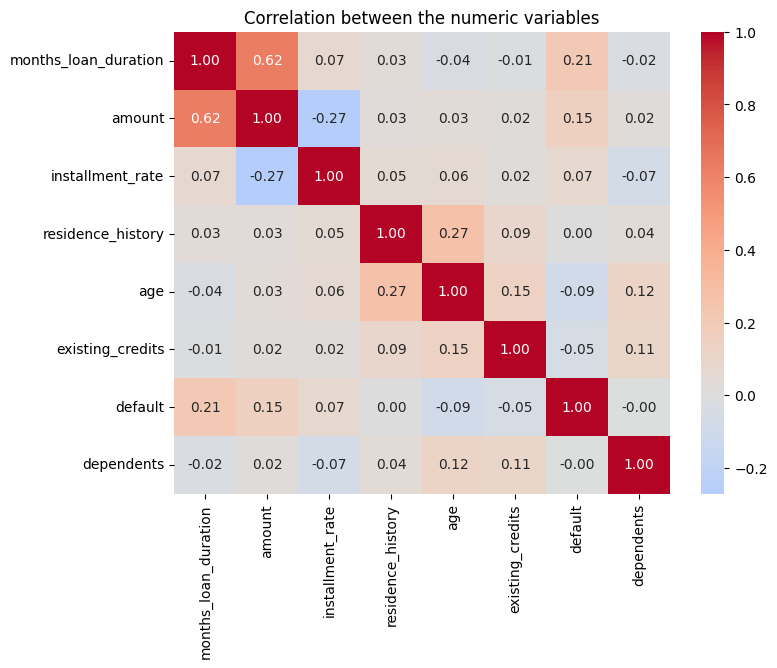

In [11]:
# Correlation between the numeric variables
numeric_columns = credit.select_dtypes(include='number').columns
correlation = credit[numeric_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation between the numeric variables')
plt.show()

A correlation heatmap puts the same variables on both axes and colors each cell
with the linear correlation of that pair, from minus one in blue to plus one in
red, with zero in white. The diagonal is always one because every variable is
perfectly correlated with itself. A value near zero means that knowing one
variable says nothing linear about the other.

The only strong pair is the amount with the duration of the loan at 0.62, which
is expected since larger loans are paid over longer terms. The next largest in
absolute value is the installment rate with the amount at -0.27, which says the
same thing from the other side, because a large loan is repaid with a smaller
share of the income. Everything else stays below 0.30.

The row of `default` is worth reading even though the response is not a
continuous variable and this measure is not the right tool for it. It gives 0.21
with the duration, 0.15 with the amount and -0.09 with the age, so the three
variables the box plots pointed at appear here too, in the same direction and
just as weak. Nothing in this table comes close to the 0.49 against 0.12 default
rate that the checking balance produced, which is the reminder that the strength
of this dataset is in its categorical columns and that a correlation matrix
cannot see them.

Trees split one variable at a time and are not disturbed by correlated
predictors the way a regression would be, so no column has to be removed because
of this, but it is useful to know that the amount and the duration carry partly
the same information when their importances are read later.

The heatmap reduces every pair of variables to one number, which hides the shape
of the relationship behind it. The pairplot draws that shape. It is built only
for the three continuous variables, since the remaining four numeric columns
take four values at most and would come out as columns of dots that say nothing.

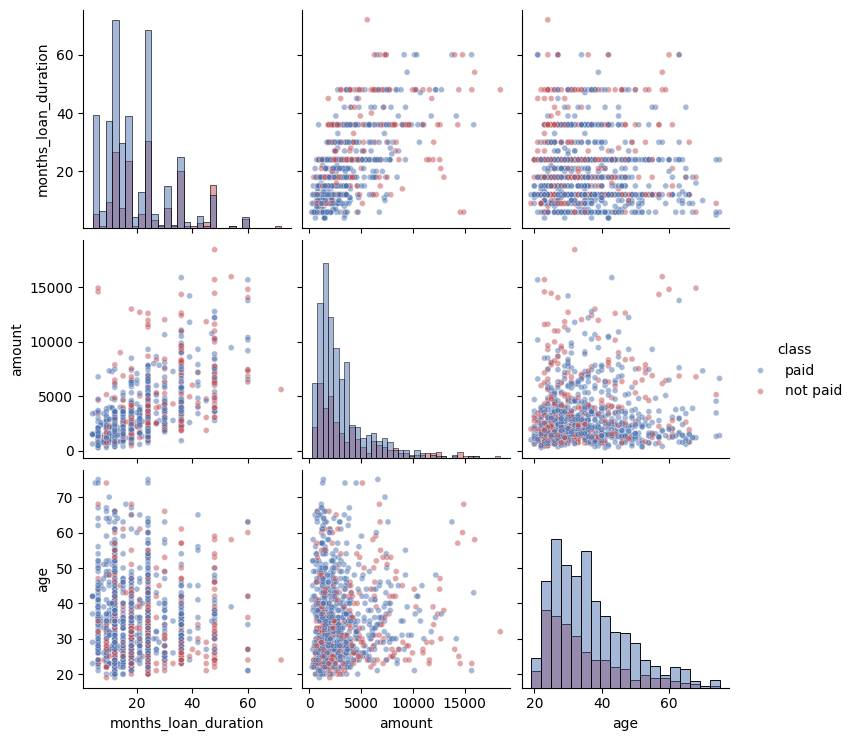

In [12]:
# Pairwise relationships of the three continuous variables, split by class
continuous = ['months_loan_duration', 'amount', 'age']
pair_data = credit[continuous].copy()
pair_data['class'] = credit['default'].map({1: 'paid', 2: 'not paid'})

sns.pairplot(pair_data, hue='class', diag_kind='hist',
             palette={'paid': '#4c72b0', 'not paid': '#c44e52'},
             plot_kws={'alpha': 0.5, 's': 18})
plt.show()

The grid puts the three variables on both axes. Each cell outside the diagonal
is a scatter plot of one variable against another, with one dot per client and
the color giving the class, and the diagonal holds the histogram of each
variable by itself, since a variable against itself would only draw a straight
line. The grid is symmetric, so the cell above the diagonal and the one below it
hold the same information with the axes swapped.

The amount against the duration is the only pair that shows a relationship. The
cloud climbs from the bottom left to the top right, which is the 0.62 of the
heatmap seen as a shape, and it does so in vertical stripes because the duration
is agreed in round terms, 6, 12, 18, 24, 36 and 48 months, rather than taking
any value. Age against the other two shows no such climb, only a cloud that
fills the space.

The colors are what this plot was drawn for, and they are mixed everywhere. The
red dots lean towards the long durations and the large amounts, and the diagonal
histogram of the age shows them piled on the young side, but there is no region
of any of these three planes that holds defaulters and nothing else. That is the
same conclusion the box plots reached, now for pairs of variables instead of one
at a time, and it sets the expectation for the rest of the notebook: a model
that separates these classes will have to combine many variables, most of them
categorical, and even then the two groups will keep overlapping.

In [13]:
# The response as a 0 and 1 variable, where 1 is the client of interest
target = (credit['default'] == 2).astype(int)

# The predictors, with every text column turned into indicator columns
predictors = pd.get_dummies(credit.drop(columns='default'))

print("Predictors before encoding:", credit.shape[1] - 1)
print("Predictors after encoding:", predictors.shape[1])
print("Class counts of the recoded response:")
print(target.value_counts().sort_index())

Predictors before encoding: 20
Predictors after encoding: 61
Class counts of the recoded response:
default
0    700
1    300
Name: count, dtype: int64


A decision tree in scikit-learn only accepts numbers, so every text column has
to be turned into numbers first. `get_dummies` replaces a column by one
indicator column per level, holding 1 when the client belongs to that level and
0 otherwise, which is why the 20 original predictors become 61 columns.

The response is recoded at the same time so that 1 means the client defaulted
and 0 means the client repaid. This is only a renaming of the labels, the counts
are still 300 and 700, and it puts the class of interest in the position that
scikit-learn treats as positive when it computes precision, recall and the ROC
curve.

Training records: 800
Test records: 200
Total: 1000

Default share in training: 0.3
Default share in test: 0.3


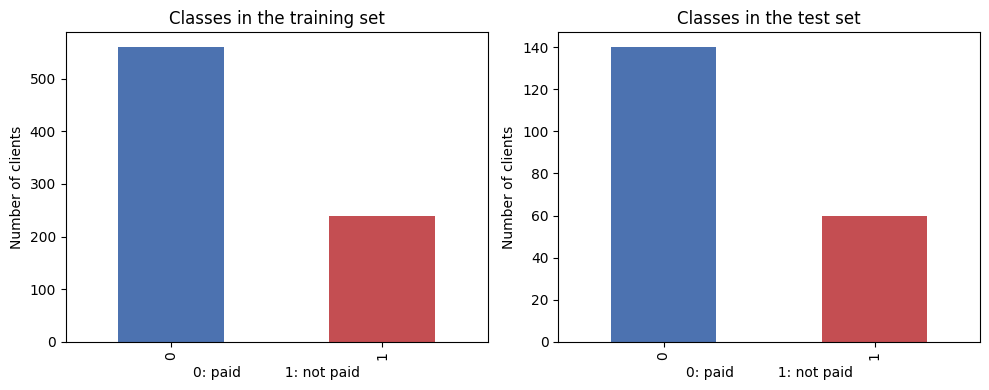

In [14]:
# Split 80 percent for training and 20 percent for testing, keeping the
# proportion of defaulters identical in both parts
X_train, X_test, y_train, y_test = train_test_split(
    predictors, target, test_size=0.2, random_state=SEED, stratify=target)

print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("Total:", len(X_train) + len(X_test))
print()
print("Default share in training:", round(y_train.mean(), 3))
print("Default share in test:", round(y_test.mean(), 3))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
y_train.value_counts().sort_index().plot(kind='bar', color=['#4c72b0', '#c44e52'])
plt.title('Classes in the training set')
plt.xlabel('0: paid          1: not paid')
plt.ylabel('Number of clients')

plt.subplot(1, 2, 2)
y_test.value_counts().sort_index().plot(kind='bar', color=['#4c72b0', '#c44e52'])
plt.title('Classes in the test set')
plt.xlabel('0: paid          1: not paid')
plt.ylabel('Number of clients')
plt.tight_layout()
plt.show()

The model is fitted on one part of the data and judged on another part it has
never seen, otherwise the score would only say how well it memorised. Here 800
records go to training and 200 to testing, and nothing is lost since the two add
up to the original 1000.

The split is stratified, which means the share of defaulters is forced to be the
same in both parts. Both bar charts show the same 70 to 30 shape and both means
print 0.3, so a difference between the two sets later on cannot be blamed on one
of them holding more defaulters than the other.

## Machine Learning Model (CRISP-DM 4: Modeling)

Two models are trained on exactly the same training set. The first one is a
single decision tree, which asks one question about one variable at each node
and sends the client left or right depending on the answer, until it reaches a
leaf that holds a class. The second one is a random forest, which grows many
trees, each on a random sample of the records and choosing among a random subset
of the variables at each node, and then lets them vote.

### Model 1: decision tree

A tree that is allowed to grow without limit keeps splitting until every leaf is
pure, which means it ends up describing the training records one by one instead
of describing the population. The depth is therefore chosen before fitting, by
trying several values and keeping the one that scores best on data the tree did
not use for that particular fit.

max_depth 2   mean AUC 0.6878
max_depth 3   mean AUC 0.6883
max_depth 4   mean AUC 0.6804
max_depth 5   mean AUC 0.6793
max_depth 6   mean AUC 0.6861
max_depth 7   mean AUC 0.6787
max_depth 8   mean AUC 0.6843
max_depth 9   mean AUC 0.6577
max_depth 10   mean AUC 0.6427
max_depth 11   mean AUC 0.6408
max_depth 12   mean AUC 0.6438

Best depth: 3


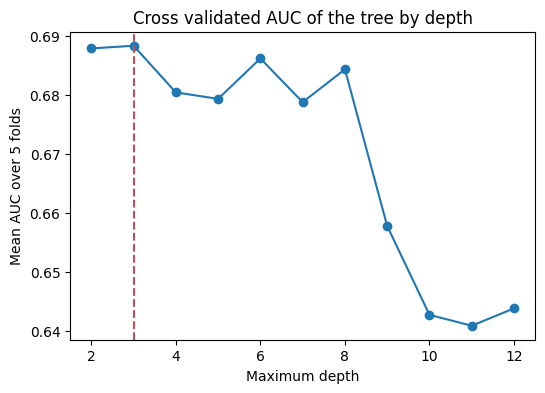

In [15]:
# Try several depths and score each one with 5 fold cross validation on the
# training set only, so the test set stays untouched
depths = range(2, 13)
scores = []
for depth in depths:
    candidate = DecisionTreeClassifier(criterion='gini', max_depth=depth,
                                       random_state=1)
    score = cross_val_score(candidate, X_train, y_train, cv=5,
                            scoring='roc_auc').mean()
    scores.append(score)
    print("max_depth", depth, "  mean AUC", round(score, 4))

best_depth = list(depths)[int(np.argmax(scores))]
print("\nBest depth:", best_depth)

plt.figure(figsize=(6, 4))
plt.plot(list(depths), scores, marker='o')
plt.axvline(best_depth, color='#c44e52', linestyle='--')
plt.title('Cross validated AUC of the tree by depth')
plt.xlabel('Maximum depth')
plt.ylabel('Mean AUC over 5 folds')
plt.show()

Cross validation cuts the training set into five blocks, fits the tree five
times leaving one block out each time, and scores it on the block that was left
out. The number reported for each depth is the average of those five scores, so
it estimates how the tree would do on new clients without ever touching the test
set. The score used is the AUC, explained in the evaluation section, where 0.5
means the model is guessing and 1 means it separates the classes perfectly.

The best depth is 3, with a mean AUC of 0.6883. That number should be read next
to its neighbours rather than on its own, because the curve is almost flat from
depth 2 to depth 8, where the scores go 0.6878, 0.6883, 0.6804, 0.6793, 0.6861,
0.6787 and 0.6843. Depth 3 wins over depth 2 by 0.0005, which is noise, so the
honest reading is not that depth 3 is the right size but that no small tree
manages to score much above 0.68 on this data.

From depth 9 onwards the curve does fall clearly, to 0.6577 and then to 0.6408
at depth 11. That fall is overfitting made visible: the deeper trees fit the
training blocks better and the held out block worse. Depth 3 is the value used
from here on.

In [16]:
# Train the decision tree with the depth chosen above
tree_model = DecisionTreeClassifier(criterion='gini', max_depth=best_depth,
                                    random_state=1)
tree_model.fit(X_train, y_train)

print("Accuracy on training:", round(tree_model.score(X_train, y_train), 3))
print("Accuracy on test:", round(tree_model.score(X_test, y_test), 3))

Accuracy on training: 0.708
Accuracy on test: 0.695


The tree is now fitted on the 800 training clients. It scores 0.708 on the
training records and 0.695 on the test ones, and the two numbers being so close
says that this tree is not memorising its training data.

The problem is the other comparison. Answering that every client pays, without
looking at a single variable, would score 0.70 on this test set, since 140 of
the 200 clients did pay. The tree scores 0.695, which is below that. Whatever it
learned, it is not buying any accuracy, and the confusion matrix in the
evaluation section shows what it is doing instead.

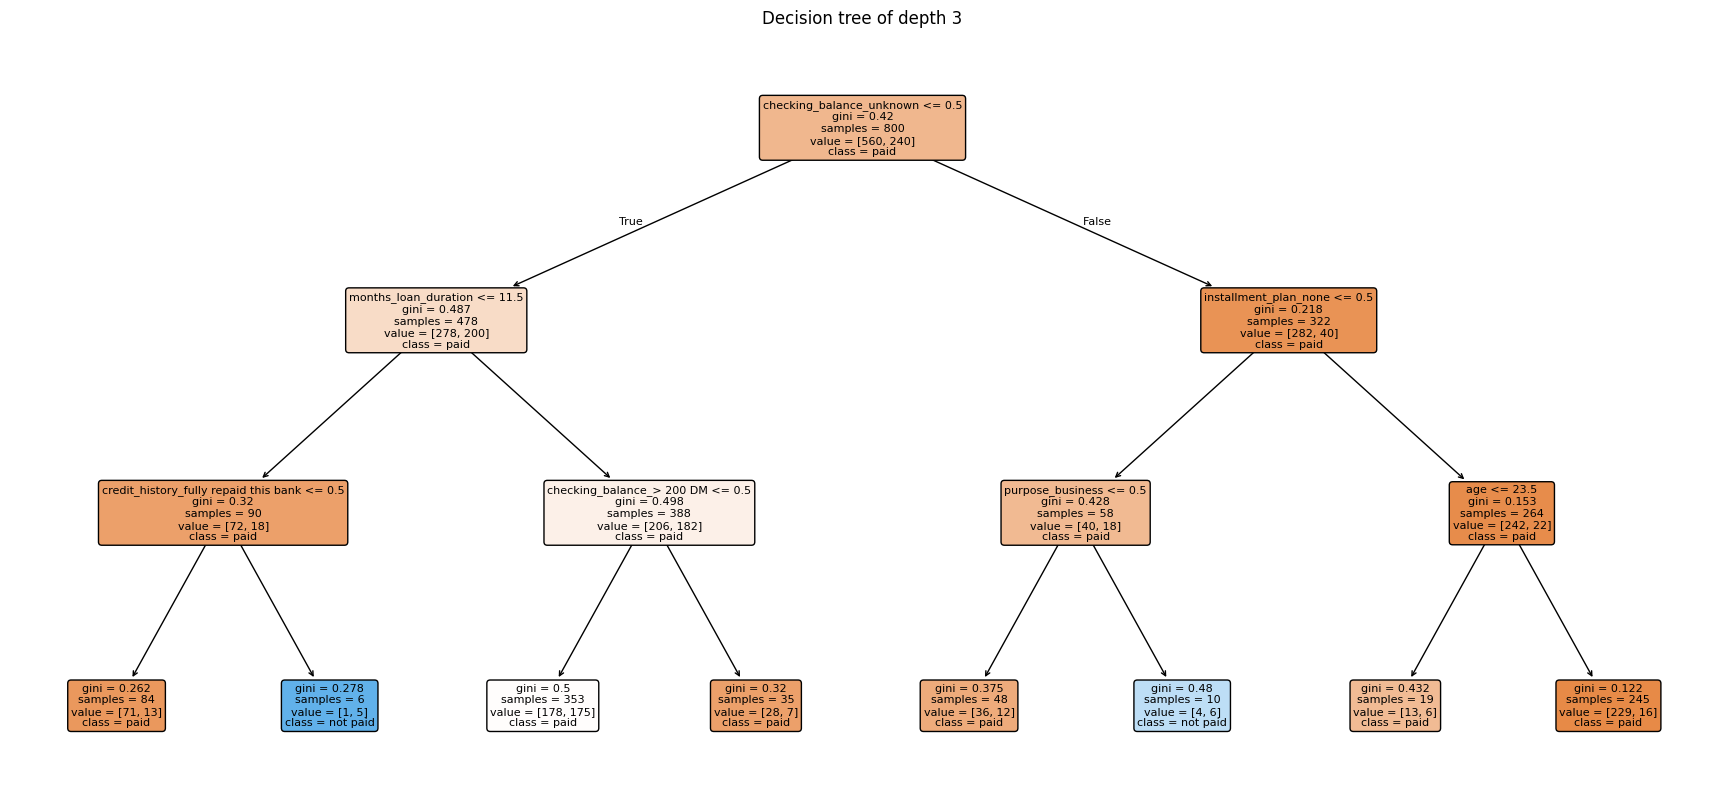

In [17]:
# Draw the tree
plt.figure(figsize=(22, 10))
plot_tree(tree_model, feature_names=list(predictors.columns),
          class_names=['paid', 'not paid'], filled=True, rounded=True,
          fontsize=8, impurity=True)
plt.title('Decision tree of depth ' + str(best_depth))
plt.show()

Every box in the drawing is a node. The first line is the question asked at that
node, and a client goes left when the answer is true and right when it is false.
Since the text variables were turned into indicator columns, a question like
`checking_balance_unknown <= 0.5` simply asks whether the client does not belong
to that level.

The second line is the gini impurity of the node, the measure the tree tries to
lower with every split. It is 0 when every client in the node belongs to the
same class and 0.5 when the node is split half and half, so a node with a low
gini is one where the answer is clear. That is the criterion passed to the model
as `criterion='gini'`. Then `samples` counts the training clients that reach the
node, `value` splits that count into the two classes in the order paid first and
not paid second, and `class` is the answer the node would give, which is simply
whichever of the two counts in `value` is larger. The color follows that same
majority, orange for the clients who paid and blue for the ones who did not, and
the stronger the color the purer the node.

The two labels come from the response built in the preparation section, where 0
means the client paid the loan back and 1 means the client defaulted. They are
not a value of any column of the dataset, and in particular the level named
repaid that appears inside `credit_history` is a predictor about previous loans,
not the variable being predicted.

The root holds the 800 training clients as `value = [560, 240]` with a gini of
0.42, and it splits on whether the client has an unknown checking balance, which
is the variable the exploration had already pointed at. What matters is what
happens below. Only two of the eight leaves come out blue, `value = [1, 5]` and
`value = [4, 6]`, which is 11 defaulters out of the 240 in training. The other
229 sit inside leaves labelled paid.

The clearest case is the leaf with `samples = 353` and `value = [178, 175]`. Its
gini is 0.500, the maximum, so that group is an even mix of clients who paid and
clients who did not, and the tree still has to print one label for all 353 of
them. It prints paid, by a margin of three clients. Reading `class` as a
description of the clients in a node is therefore the easy mistake to make, and
the honest reading of a node is its `value` and its gini.

                             Variable  Importance
             checking_balance_unknown    0.522390
                 months_loan_duration    0.165936
            checking_balance_> 200 DM    0.087381
credit_history_fully repaid this bank    0.080897
                installment_plan_none    0.076882
                                  age    0.034708
                     purpose_business    0.031806
                    residence_history    0.000000
                     installment_rate    0.000000
              checking_balance_< 0 DM    0.000000


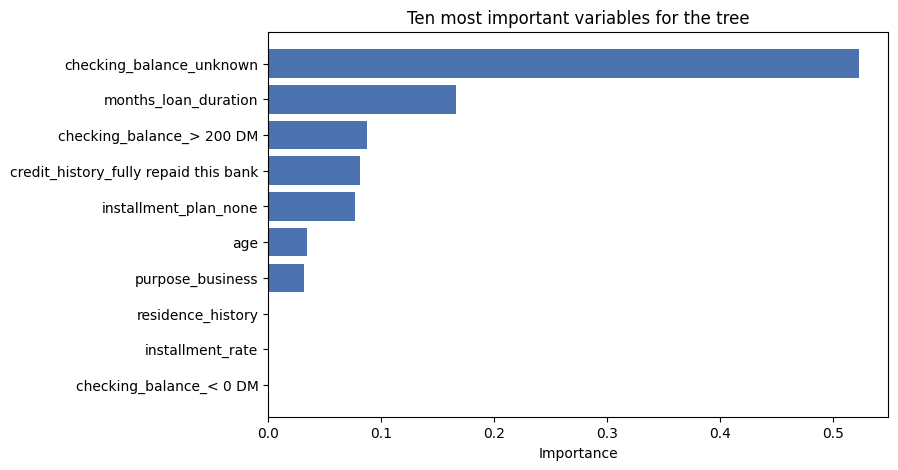

In [18]:
# Importance of each variable for the tree
tree_importances = pd.DataFrame({
    'Variable': tree_model.feature_names_in_,
    'Importance': tree_model.feature_importances_
}).sort_values('Importance', ascending=False)

top_tree = tree_importances.head(10)
print(top_tree.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(top_tree['Variable'][::-1], top_tree['Importance'][::-1], color='#4c72b0')
plt.title('Ten most important variables for the tree')
plt.xlabel('Importance')
plt.show()

The importance of a variable is how much the splits made on it reduced the
impurity of the nodes, weighted by how many training clients passed through
those splits, and the importances of all the variables add up to 1. A variable
with importance 0 was never used.

This tree is extremely concentrated. The indicator of an unknown checking
balance alone takes 0.522 of the total, the duration of the loan takes 0.166 and
the indicator of a checking balance above 200 DM takes 0.087. Only 7 of the 61
columns get any importance at all, so 54 of them were never used, which the
count printed in the next model makes explicit.

That is what makes a single tree easy to explain and, at the same time, fragile.
Four levels of questions can only look at a handful of variables, and everything
the dataset knows about savings, employment, property or the purpose of the loan
is simply discarded.

### Model 2: random forest

The random forest grows 500 trees. Each one is fitted on a bootstrap sample of
the training records, which is a sample of the same size drawn with replacement,
and at each node it may only choose among a random subset of the variables. The
trees are therefore different from one another, and the class the forest reports
is the one most of them vote for. Averaging many noisy trees cancels part of
that noise, which is why the forest is expected to beat the single tree.

In [19]:
# Train the random forest on the same training set
forest_model = RandomForestClassifier(n_estimators=500, random_state=1)
forest_model.fit(X_train, y_train)

print("Accuracy on training:", round(forest_model.score(X_train, y_train), 3))
print("Accuracy on test:", round(forest_model.score(X_test, y_test), 3))

Accuracy on training: 1.0
Accuracy on test: 0.775


The training accuracy of the forest is exactly 1.0, because each of its trees
was grown without a depth limit until its leaves were pure, so that number says
nothing about the quality of the model. The test accuracy is 0.775, which is 8
points above the single tree and 7.5 points above the 0.70 that answering paid
to everybody would already give.

Eight points of accuracy is a modest gain, and it is not where the real
difference between the two models shows up. That appears in the ROC curve and in
the confusion matrices of the next section.

                Variable  Importance
                  amount    0.098218
    months_loan_duration    0.078529
                     age    0.077062
checking_balance_unknown    0.049219
 checking_balance_< 0 DM    0.038254
        installment_rate    0.032945
       residence_history    0.032152
       purpose_car (new)    0.019770
 credit_history_critical    0.019734
savings_balance_< 100 DM    0.018613

Variables the forest never used: 0
Variables the tree never used: 54


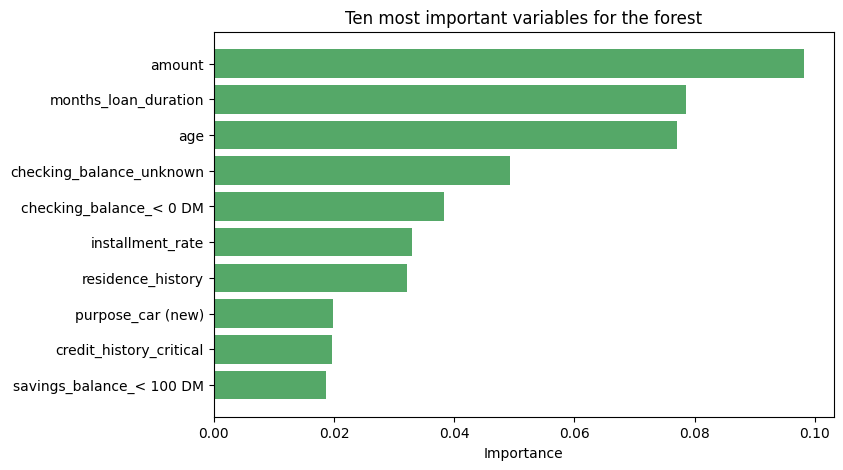

In [20]:
# Importance of each variable for the forest
forest_importances = pd.DataFrame({
    'Variable': forest_model.feature_names_in_,
    'Importance': forest_model.feature_importances_
}).sort_values('Importance', ascending=False)

top_forest = forest_importances.head(10)
print(top_forest.to_string(index=False))

print("\nVariables the forest never used:",
      int((forest_importances['Importance'] == 0).sum()))
print("Variables the tree never used:",
      int((tree_importances['Importance'] == 0).sum()))

plt.figure(figsize=(8, 5))
plt.barh(top_forest['Variable'][::-1], top_forest['Importance'][::-1], color='#55a868')
plt.title('Ten most important variables for the forest')
plt.xlabel('Importance')
plt.show()

The importances are computed the same way as for the tree, but averaged over the
500 trees. The ranking changes and, more importantly, it flattens. The largest
importance is 0.098 for the amount of the loan, followed by the duration with
0.079 and the age with 0.077, where the single tree had one variable holding
0.522. The counts printed above say the rest: the forest used all 61 columns and
the tree left 54 of them untouched, because each tree is offered a different
random subset of columns and the rare levels get their chance.

The three variables that lead the list are the ones with many distinct values,
and this measure of importance is known to favour them, because a variable with
many possible cut points gets more opportunities to produce a good split. So the
ranking should not be read as saying that the amount is what decides whether a
client defaults. The exploration measured that directly, and the variable that
separates the two classes is the checking balance, which goes from 12 percent of
defaults when it is unknown to 49 percent when the account is overdrawn. Its two
indicators are the next ones in the forest ranking, with 0.049 and 0.038.

## Evaluation (CRISP-DM 5)

Both models are now applied to the 200 test clients they have never seen, of
which 60 defaulted and 140 repaid. The first tool is the confusion matrix, which
crosses the real class with the predicted one. Its four cells are the clients correctly predicted as repaying,
the clients wrongly flagged as defaulters, the defaulters the model let through,
and the defaulters it caught. For this problem the third cell is the expensive
one.

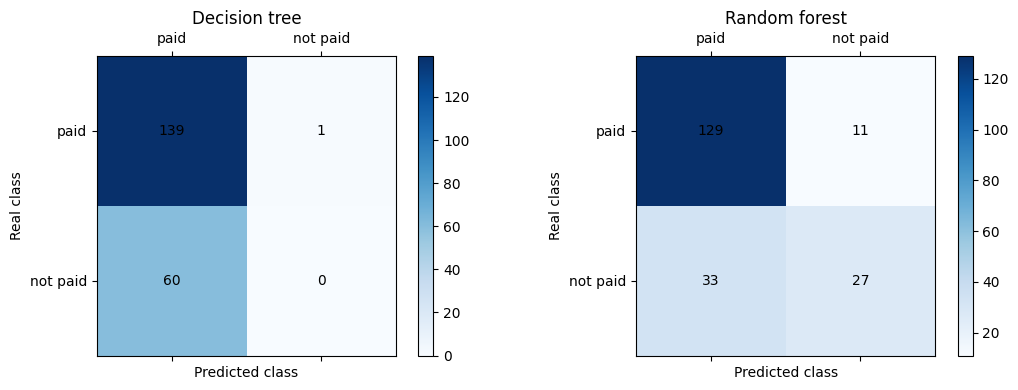

Decision tree
              precision    recall  f1-score   support

        paid      0.698     0.993     0.820       140
    not paid      0.000     0.000     0.000        60

    accuracy                          0.695       200
   macro avg      0.349     0.496     0.410       200
weighted avg      0.489     0.695     0.574       200

Random forest
              precision    recall  f1-score   support

        paid      0.796     0.921     0.854       140
    not paid      0.711     0.450     0.551        60

    accuracy                          0.780       200
   macro avg      0.753     0.686     0.703       200
weighted avg      0.771     0.780     0.763       200



In [21]:
# Probability of default that each model assigns to every test client
tree_scores = tree_model.predict_proba(X_test)[:, 1]
forest_scores = forest_model.predict_proba(X_test)[:, 1]

# One single rule turns those probabilities into decisions. Every matrix, table
# and cost of this section goes through it, so the models are always compared
# under the same cut and never through predict(), which resolves a probability
# of exactly 0.5 towards the class that pays
DECISION_THRESHOLD = 0.5

def decisions_at(scores, threshold):
    return (scores >= threshold).astype(int)

tree_predictions = decisions_at(tree_scores, DECISION_THRESHOLD)
forest_predictions = decisions_at(forest_scores, DECISION_THRESHOLD)

tree_matrix = confusion_matrix(y_test, tree_predictions)
forest_matrix = confusion_matrix(y_test, forest_predictions)

labels = ['paid', 'not paid']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, matrix, name in zip(axes, [tree_matrix, forest_matrix],
                            ['Decision tree', 'Random forest']):
    image = ax.matshow(matrix, cmap=plt.cm.Blues)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(x=j, y=i, s=matrix[i, j], va='center', ha='center')
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Real class')
    ax.set_xticks([0, 1], labels)
    ax.set_yticks([0, 1], labels)
    ax.set_title(name)
    fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

print("Decision tree")
print(classification_report(y_test, tree_predictions,
                            target_names=labels, digits=3))
print("Random forest")
print(classification_report(y_test, forest_predictions,
                            target_names=labels, digits=3))

In each matrix the rows are the real class and the columns the predicted one, so
the diagonal holds the correct answers. The report under the plots turns the
same four cells into three rates, computed here for the defaulters. Precision is
how many of the clients flagged as defaulters really defaulted, recall is how
many of the real defaulters the model flagged, and the F1 is the balance between
those two.

The tree does not classify anything. Of the 140 clients who paid it predicts
paid for 139, and of the 60 who defaulted it catches 0. Its recall and its
precision on the defaulters are both 0.000, and its accuracy of 0.695 is simply
the share of clients who paid. This is the same model as answering paid to
everybody, and the drawing of the tree already announced it: the only two leaves
that predict a default hold 6 and 10 training clients between them, and no test
defaulter landed in either.

The forest does classify. It catches 27 of the 60 defaulters, a recall of 0.450,
and of the 38 clients it flags 27 really defaulted, a precision of 0.711. It
still lets 33 defaulters through, so it is far from solving the problem, but
unlike the tree it produces decisions at all. Its accuracy of 0.780 is 8.5
points above the tree.

Both models were asked for a decision at the same cut of 0.5 applied to the
probability they assign, which is what `decisions_at` does, so the difference
between them is the model and not the rule.

AUC of the decision tree: 0.693
AUC of the random forest: 0.818


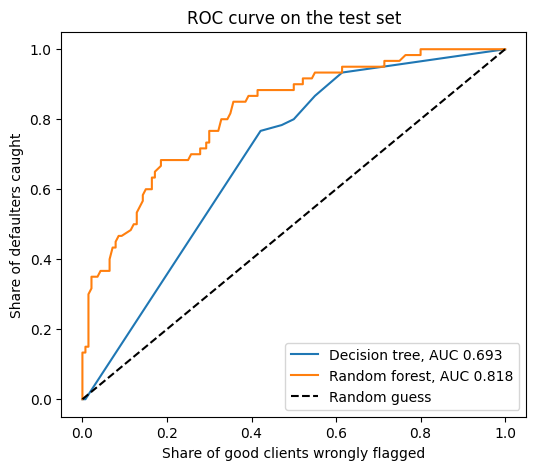

In [22]:
# ROC curve of both models, built from the probabilities computed above
tree_auc = roc_auc_score(y_test, tree_scores)
forest_auc = roc_auc_score(y_test, forest_scores)
print("AUC of the decision tree:", round(tree_auc, 3))
print("AUC of the random forest:", round(forest_auc, 3))

fpr_tree, tpr_tree, _ = roc_curve(y_test, tree_scores)
fpr_forest, tpr_forest, _ = roc_curve(y_test, forest_scores)

plt.figure(figsize=(6, 5))
plt.plot(fpr_tree, tpr_tree, label='Decision tree, AUC ' + str(round(tree_auc, 3)))
plt.plot(fpr_forest, tpr_forest, label='Random forest, AUC ' + str(round(forest_auc, 3)))
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('Share of good clients wrongly flagged')
plt.ylabel('Share of defaulters caught')
plt.title('ROC curve on the test set')
plt.legend()
plt.show()

Both models do not really answer yes or no, they return a probability of
default, and the predictions compared above came from cutting that probability
at 0.5. The ROC curve redoes the comparison for every possible cut: the
horizontal axis is the share of good clients wrongly flagged and the vertical
one the share of defaulters caught, and each point of the curve is one cut. The
diagonal is what a coin flip would draw. The area under the curve, the AUC,
summarises it in one number, and it can be read as the probability that the
model gives a higher score to a random defaulter than to a random client who
pays.

Here the two models separate for real. The forest reaches an AUC of 0.818 and
the tree only 0.693, a gap of 0.125, and the curve of the forest sits above the
one of the tree along almost the whole range. So the forest does order the
clients by risk much better, and the 33 defaulters it let through are a problem
of where the cut was placed rather than of the ordering it produces. The tree,
at 0.693, is barely better at ranking than at deciding, and its curve is made of
the few steps its eight leaves allow.

That difference is what the next cell exploits. A model that ranks well can be
made stricter by lowering the cut, while a model whose probabilities never reach
0.5, which is the case of the tree, has nothing to move.

In [23]:
# What happens to the forest when the cut is moved away from 0.5, using the
# same decision rule as the confusion matrices
rows = []
for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    predicted = decisions_at(forest_scores, threshold)
    rows.append({
        'Threshold': threshold,
        'Accuracy': round(accuracy_score(y_test, predicted), 3),
        'Precision': round(precision_score(y_test, predicted), 3),
        'Recall': round(recall_score(y_test, predicted), 3),
        'F1': round(f1_score(y_test, predicted), 3),
        'Missed defaulters': int(((y_test == 1) & (predicted == 0)).sum()),
        'Good clients rejected': int(((y_test == 0) & (predicted == 1)).sum())
    })
print(pd.DataFrame(rows).to_string(index=False))

 Threshold  Accuracy  Precision  Recall    F1  Missed defaulters  Good clients rejected
      0.20     0.595      0.421   0.933 0.580                  4                     77
      0.25     0.615      0.431   0.883 0.579                  7                     70
      0.30     0.685      0.486   0.867 0.623                  8                     55
      0.35     0.715      0.518   0.717 0.601                 17                     40
      0.40     0.770      0.603   0.683 0.641                 19                     27
      0.45     0.770      0.630   0.567 0.596                 26                     20
      0.50     0.780      0.711   0.450 0.551                 33                     11


Each row applies a different cut to the same probabilities of the forest and
recounts the errors. Lowering the cut means flagging a client as a defaulter on
weaker evidence, so more defaulters are caught and more good clients are
rejected at the same time. The two columns on the right count those two mistakes
directly, so the table can be read as a menu of decisions rather than as a list
of scores.

At the cut of 0.5 the forest misses 33 defaulters and rejects 11 good clients.
At 0.30 it misses 8 and rejects 55, and its recall climbs from 0.450 to 0.867.
Accuracy moves the other way, from 0.780 down to 0.685, which is the whole point
of the table: the cut that maximises accuracy and the cut that protects the bank
are not the same cut.

Under the five to one cost of this dataset, one missed defaulter is worth five
rejected good clients, so the first option costs 33 times 5 plus 11, that is 176
units, and the second costs 8 times 5 plus 55, that is 95 units. The next cell
computes that for every cut instead of these seven.

Cost of the tree at 0.5: 301
Cost of the forest at 0.5: 176
Cheapest cut for the forest: 0.28
Cost of the forest at that cut: 93


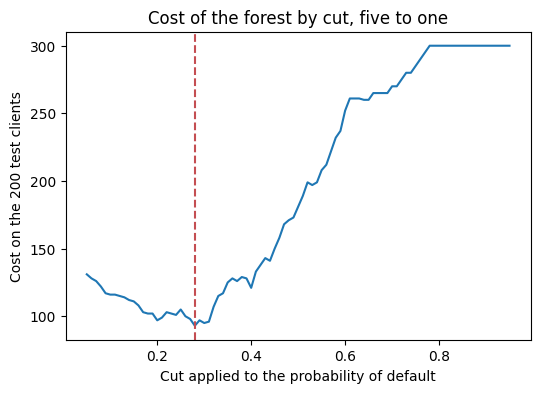

In [24]:
# Cost of every cut under the five to one rule, including both models at 0.5
COST_MISSED_DEFAULTER = 5
COST_REJECTED_CLIENT = 1

def total_cost(scores, threshold):
    predicted = decisions_at(scores, threshold)
    missed = ((y_test == 1) & (predicted == 0)).sum()
    rejected = ((y_test == 0) & (predicted == 1)).sum()
    return missed * COST_MISSED_DEFAULTER + rejected * COST_REJECTED_CLIENT

grid = np.arange(0.05, 0.96, 0.01)
forest_costs = [total_cost(forest_scores, t) for t in grid]
best_threshold = grid[int(np.argmin(forest_costs))]

print("Cost of the tree at 0.5:", total_cost(tree_scores, 0.5))
print("Cost of the forest at 0.5:", total_cost(forest_scores, 0.5))
print("Cheapest cut for the forest:", round(best_threshold, 2))
print("Cost of the forest at that cut:", total_cost(forest_scores, best_threshold))

plt.figure(figsize=(6, 4))
plt.plot(grid, forest_costs)
plt.axvline(best_threshold, color='#c44e52', linestyle='--')
plt.title('Cost of the forest by cut, five to one')
plt.xlabel('Cut applied to the probability of default')
plt.ylabel('Cost on the 200 test clients')
plt.show()

This last plot puts the cut on the horizontal axis and the total cost of the
resulting decisions on the vertical one, counting five units for every defaulter
approved and one unit for every good client turned away. Lower is better, and
the dashed line marks the cheapest cut.

The curve is clearly U shaped. Being too strict rejects almost everybody and
being too permissive approves every defaulter, and the minimum sits in between.
Choosing the cut this way is not tuning the model to look better: the forest is
the same, only the point at which its probabilities become a decision is set
from the cost the bank actually pays instead of from the default 0.5.

## Results (CRISP-DM 6: Deployment)

Two models were trained on the same 800 clients and judged on the same 200. The
decision tree, whose depth of 3 was chosen by cross validation, reaches an
accuracy of 0.695 and an AUC of 0.693. The random forest of 500 trees reaches an
accuracy of 0.775 and an AUC of 0.818. The forest is the better model on both
counts, and the gap of 0.125 in AUC is the one that matters, since it says the
forest orders the clients by risk more reliably no matter where the decision cut
is later placed.

The tree, as it came out of the cross validation, is not usable at all. It
catches 0 of the 60 defaulters of the test set, its recall and its precision on
that class are both 0.000, and its accuracy of 0.695 is below the 0.70 that
answering paid to everybody would give. Its cross validation curve explains why:
every depth from 2 to 8 scores between 0.678 and 0.688, a range of one hundredth
of AUC, so the procedure was choosing between sizes that are all equally weak
rather than finding a good one. With eight leaves, none of which reaches a
majority of defaulters on the test set, the model has no way to answer anything
but paid.

The forest does work, and it is still not good enough to approve or reject a
loan on its own. At the cut of 0.5 it catches 27 of the 60 defaulters and lets
33 through. The reason is visible in the exploration: the variables of this
dataset overlap heavily between the two classes, no single one of them separates
a defaulter from a client who pays, and the strongest signal, the balance of the
checking account, is missing for the very group that turns out to be the safest,
since the clients with no account at this bank default 12 percent of the time
against 49 percent for those who are overdrawn.

Moving the cut is what turns the forest into something useful. Counting five
units for every defaulter approved and one unit for every good client turned
away, the tree costs 301 units on these 200 clients, the forest at the cut of
0.5 costs 176, and the forest at its cheapest cut of 0.28 costs 93. That last
number is a third of what the tree costs and about half of what the default cut
costs, and the trade behind it is explicit: at a cut of 0.30 the share of
defaulters caught goes from 45 percent to 87 percent while accuracy falls from
0.780 to 0.685. Around 10 points of accuracy are given up in exchange for 25 of
the 33 defaulters that the default cut was letting through.

The recommendation is to use the forest as a scoring tool rather than as an
automatic decision, with the cut chosen from the cost the bank assigns to each
error and not from the default 0.5, and to keep the tree next to it only as an
explanation of what drives the risk, since its few levels can be read out loud
to an applicant while the forest cannot. The tree should not be used to decide
anything, and this notebook does not recommend it as a model.

Four limitations should be stated. The dataset holds 1000 records and only 300
defaulters, so every metric reported here is measured on the 60 defaulters of
the test set, and one client moving from one cell of the matrix to another
changes recall by almost two points. The cut of 0.28 was chosen on the same test
set it is evaluated on, so its cost of 93 units is optimistic, and a honest
deployment would pick the cut on a third split or inside the cross validation.
The data is old and German, with amounts in Deutsche Mark, so the risk it
encodes does not transfer to another market without being refitted. And the
importances of the forest favour the variables with many distinct values, so the
fact that the amount, the age and the duration lead the ranking should be read
together with the tables of the exploration, where the checking balance is the
variable that actually separates the two classes.